In [2]:
import pandas as pd

In [10]:
results = pd.read_csv('/Users/nicholaskim/Documents/Repositories/black jack monte carlo/result.csv')
print(results)

     hand_value dealer_show_value  hit_ev  stand_ev
0             4                 2 -0.2898   -0.3058
1             4                 3 -0.2356   -0.2492
2             4                 4 -0.1884   -0.1940
3             4                 5 -0.1184   -0.1214
4             4                 6 -0.1296   -0.1340
..          ...               ...     ...       ...
175          21                 7  1.0000    1.0000
176          21                 8  1.0000    1.0000
177          21                 9  1.0000    1.0000
178          21                10  0.9189    0.9171
179          21                 A  0.6883    0.6829

[180 rows x 4 columns]


In [11]:
import numpy as np 

results['win'] = np.where(results['hit_ev'] > results['stand_ev'], 'hit', 'stand')
results['diff'] = results['hit_ev'] - results['stand_ev']

results


,hand_value,dealer_show_value,hit_ev,stand_ev,win,diff
0,4,2,-0.2898,-0.3058,hit,0.0160
1,4,3,-0.2356,-0.2492,hit,0.0136
2,4,4,-0.1884,-0.1940,hit,0.0056
3,4,5,-0.1184,-0.1214,hit,0.0030
4,4,6,-0.1296,-0.1340,hit,0.0044
...,...,...,...,...,...,...
175,21,7,1.0000,1.0000,stand,0.0000
176,21,8,1.0000,1.0000,stand,0.0000
177,21,9,1.0000,1.0000,stand,0.0000
178,21,10,0.9189,0.9171,hit,0.0018


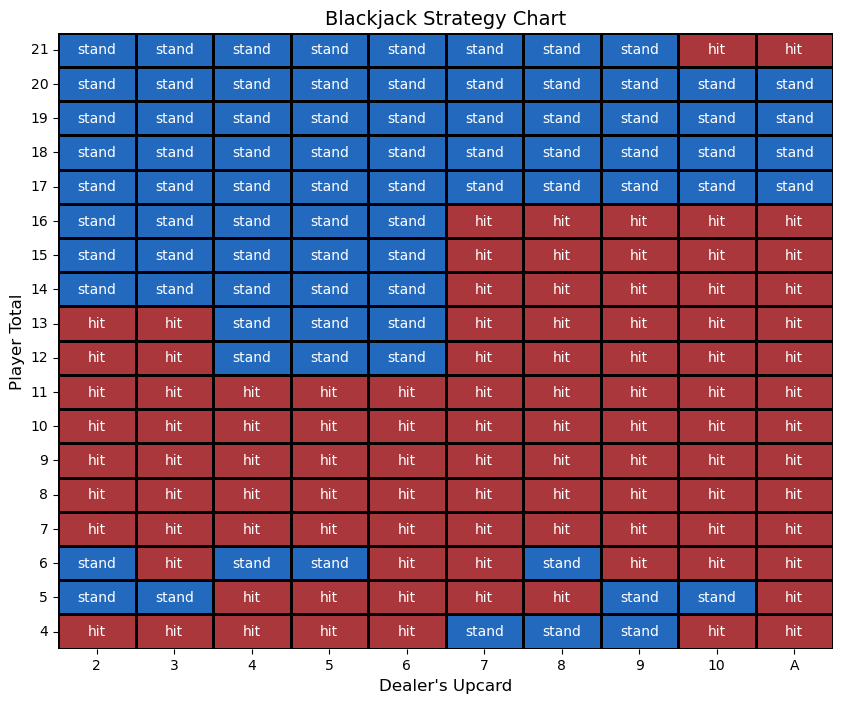

In [32]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

results = pd.read_csv('/Users/nicholaskim/Documents/Repositories/black jack monte carlo/result.csv')

# 'A' mixes with ints, so make the dealer column strings for consistent ordering
results['dealer_show_value'] = results['dealer_show_value'].astype(str)
results['win'] = np.where(results['hit_ev'] > results['stand_ev'], 'hit', 'stand')

dealer_order = ['2', '3', '4', '5', '6', '7', '8', '9', '10', 'A']

strat = (
    results.pivot(index='hand_value', columns='dealer_show_value', values='win')
    [dealer_order]                      # columns: 2 ... A
    .sort_index(ascending=False)        # rows: 21 at the top down to 4, like printed charts
)

numeric = (strat == 'hit').astype(int)  # 1 = hit, 0 = stand

plt.figure(figsize=(10, 8))
ax = sns.heatmap(
    numeric,
    annot=strat,
    fmt='',
    cmap='vlag',
    cbar=False,
    linewidths=1,
    linecolor='black',
)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel("Dealer's Upcard", fontsize=12)
ax.set_ylabel('Player Total', fontsize=12)
ax.set_title('Blackjack Strategy Chart', fontsize=14)
plt.show()

In [37]:
results['diff'] = results['hit_ev'] - results['stand_ev']
diff_ordered = results.sort_values('diff', ascending=True)
diff_ordered.loc[diff_ordered['diff'] > 0,:]

,hand_value,dealer_show_value,hit_ev,stand_ev,win,diff
16,5,8,-0.5268,-0.5278,hit,0.0010
12,5,4,-0.1710,-0.1726,hit,0.0016
178,21,10,0.9189,0.9171,hit,0.0018
19,5,A,-0.7502,-0.7528,hit,0.0026
3,4,5,-0.1184,-0.1214,hit,0.0030
...,...,...,...,...,...,...
77,11,9,0.1197,-0.5216,hit,0.6413
66,10,8,0.1697,-0.4962,hit,0.6659
76,11,8,0.1676,-0.5166,hit,0.6842
65,10,7,0.2254,-0.4880,hit,0.7134


In [21]:
results.loc[results['hand_value']==21,:]

,hand_value,dealer_show_value,hit_ev,stand_ev,win,diff
170,21,2,1.0000,1.0000,stand,0.0000
171,21,3,1.0000,1.0000,stand,0.0000
172,21,4,1.0000,1.0000,stand,0.0000
173,21,5,1.0000,1.0000,stand,0.0000
174,21,6,1.0000,1.0000,stand,0.0000
175,21,7,1.0000,1.0000,stand,0.0000
176,21,8,1.0000,1.0000,stand,0.0000
177,21,9,1.0000,1.0000,stand,0.0000
178,21,10,0.9189,0.9171,hit,0.0018
179,21,A,0.6883,0.6829,hit,0.0054
